In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("../data/creditcard.csv")

# Display first five records
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [2]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nMissing Values:", df.isnull().sum().sum())

print("\nDuplicate Records:", df.duplicated().sum())

Dataset Shape: (284807, 31)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20

In [3]:
print(df["Class"].value_counts())

print("\nPercentage Distribution:")
print(df["Class"].value_counts(normalize=True) * 100)

Class
0    284315
1       492
Name: count, dtype: int64

Percentage Distribution:
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


Legitimate Transactions: 284315
Fraudulent Transactions: 492


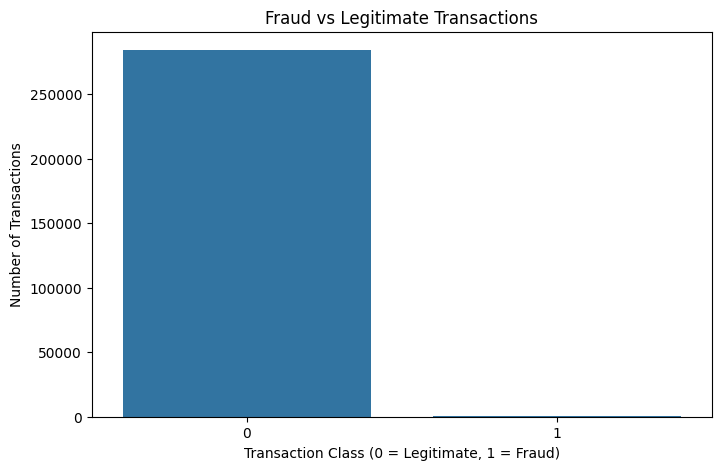

In [4]:
# Count transactions by class
class_counts = df["Class"].value_counts()

print("Legitimate Transactions:", class_counts[0])
print("Fraudulent Transactions:", class_counts[1])

# Visualize class distribution
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Class")

plt.title("Fraud vs Legitimate Transactions")
plt.xlabel("Transaction Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Number of Transactions")

plt.show()

In [5]:
fraud_percentage = (
    df["Class"].value_counts(normalize=True) * 100
)

print(fraud_percentage)

Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


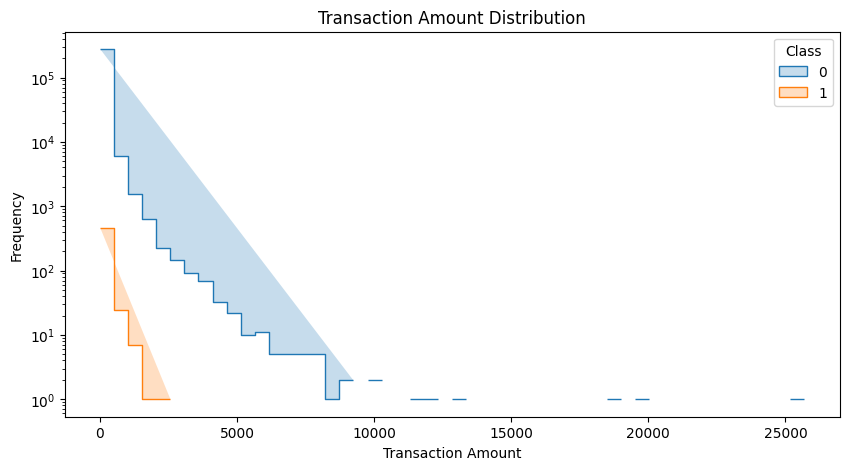

In [6]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Amount",
    hue="Class",
    bins=50,
    log_scale=(False, True),
    element="step"
)

plt.title("Transaction Amount Distribution")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")

plt.show()

In [7]:
df.groupby("Class")["Amount"].describe()

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0,88.291022,250.105092,0.0,5.65,22.00,77.05,25691.16
1,492.0,122.211321,256.683288,0.0,1.00,9.25,105.89,2125.87


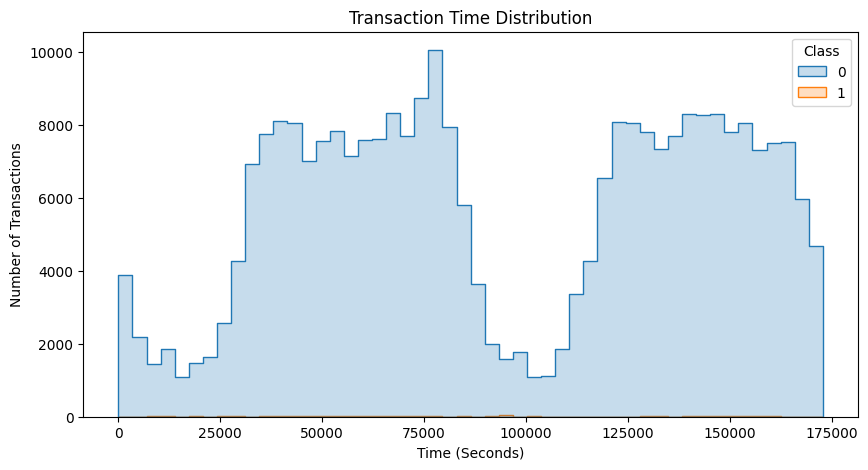

In [8]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Time",
    hue="Class",
    bins=50,
    element="step"
)

plt.title("Transaction Time Distribution")
plt.xlabel("Time (Seconds)")
plt.ylabel("Number of Transactions")

plt.show()

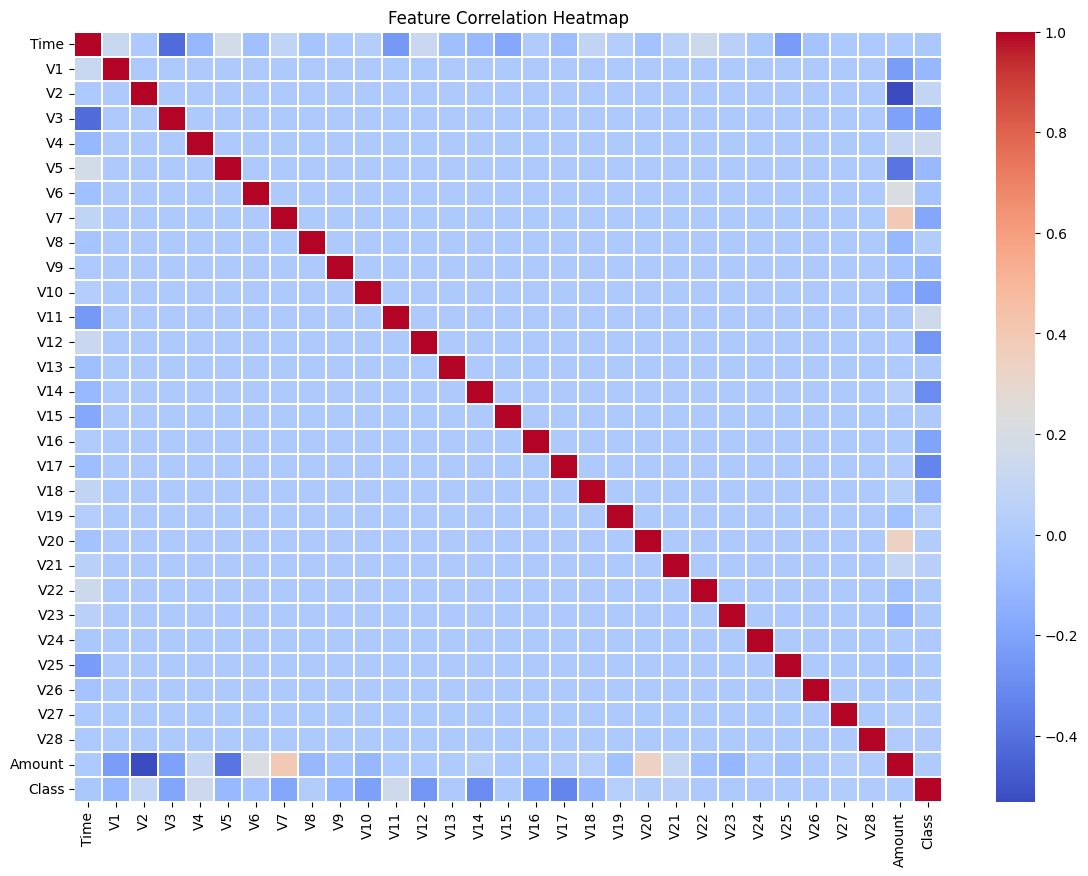

In [9]:
plt.figure(figsize=(14, 10))

correlation = df.corr()

sns.heatmap(
    correlation,
    cmap="coolwarm",
    linewidths=0.1
)

plt.title("Feature Correlation Heatmap")

plt.show()

In [10]:
### 3.1 Duplicate Analysis

# Count duplicate records
duplicate_count = df.duplicated().sum()

print("Total Records:", len(df))
print("Duplicate Records:", duplicate_count)
print("Duplicate Percentage:", round(
    (duplicate_count / len(df)) * 100, 2
), "%")

Total Records: 284807
Duplicate Records: 1081
Duplicate Percentage: 0.38 %


In [11]:
duplicate_rows = df[df.duplicated(keep=False)]

print(duplicate_rows["Class"].value_counts())

Class
0    1822
1      32
Name: count, dtype: int64


In [12]:
# Create a clean copy
df_clean = df.drop_duplicates().copy()

print("Original Shape:", df.shape)
print("Cleaned Shape:", df_clean.shape)
print("Duplicates Remaining:", df_clean.duplicated().sum())

Original Shape: (284807, 31)
Cleaned Shape: (283726, 31)
Duplicates Remaining: 0


In [13]:
# 3.2 – Check missing values
missing_values = df_clean.isnull().sum()

print("Total Missing Values:", missing_values.sum())

print("\nMissing Values by Column:")
print(missing_values[missing_values > 0])

Total Missing Values: 0

Missing Values by Column:
Series([], dtype: int64)


In [16]:
# 3.3 – Separate features and target variable


# Independent variables
X = df_clean.drop("Class", axis=1)

# Dependent variable
y = df_clean["Class"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Distribution:")
print(y.value_counts())

Features Shape: (283726, 30)
Target Shape: (283726,)

Target Distribution:
Class
0    283253
1       473
Name: count, dtype: int64


In [17]:
# 3.4 – Train-test split
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())

Training Features: (226980, 30)
Testing Features: (56746, 30)

Training Target Distribution:
Class
0    226602
1       378
Name: count, dtype: int64

Testing Target Distribution:
Class
0    56651
1       95
Name: count, dtype: int64


In [18]:
# 3.5 – Feature scaling

from sklearn.preprocessing import StandardScaler

# Initialize scaler
scaler = StandardScaler()

# Fit only on training data
X_train[["Time", "Amount"]] = scaler.fit_transform(
    X_train[["Time", "Amount"]]
)

# Transform testing data using the same scaler
X_test[["Time", "Amount"]] = scaler.transform(
    X_test[["Time", "Amount"]]
)

print("Feature scaling completed!")

print(X_train[["Time", "Amount"]].describe())

Feature scaling completed!
               Time        Amount
count  2.269800e+05  2.269800e+05
mean  -1.518880e-16  7.309531e-17
std    1.000002e+00  1.000002e+00
min   -1.998400e+00 -3.596386e-01
25%   -8.561822e-01 -3.364866e-01
50%   -2.123526e-01 -2.697972e-01
75%    9.363191e-01 -4.287453e-02
max    1.640237e+00  7.962087e+01


In [19]:

# 3.6 – Verify our processed dataset


print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nMissing Values in Training:", X_train.isnull().sum().sum())
print("Missing Values in Testing:", X_test.isnull().sum().sum())

print("\nFraud in Training:", y_train.value_counts()[1])
print("Fraud in Testing:", y_test.value_counts()[1])

Training Data Shape: (226980, 30)
Testing Data Shape: (56746, 30)

Missing Values in Training: 0
Missing Values in Testing: 0

Fraud in Training: 378
Fraud in Testing: 95


In [20]:
# 3.7 – Save the preprocessing objects

import joblib
import os

os.makedirs("../models", exist_ok=True)

joblib.dump(scaler, "../models/scaler.pkl")

print("Scaler saved successfully!")

Scaler saved successfully!


In [21]:
# 4.3 – Import ML algorithms

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

import pandas as pd
import numpy as np
import time

print("All ML algorithms imported successfully!")

All ML algorithms imported successfully!


In [22]:
# 4.4 – Initialize the models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=6,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=200,
        max_depth=5,
        learning_rate=0.1,
        random_state=42,
        eval_metric="logloss",
        n_jobs=-1
    )
}

print("Models initialized successfully!")

Models initialized successfully!


In [23]:
# 4.5 – Train all four models

trained_models = {}

for name, model in models.items():

    print(f"\nTraining {name}...")

    start_time = time.time()

    model.fit(X_train, y_train)

    end_time = time.time()

    trained_models[name] = model

    print(f"{name} trained successfully!")
    print(f"Training Time: {end_time - start_time:.2f} seconds")


Training Logistic Regression...
Logistic Regression trained successfully!
Training Time: 0.34 seconds

Training Decision Tree...
Decision Tree trained successfully!
Training Time: 10.33 seconds

Training Random Forest...
Random Forest trained successfully!
Training Time: 71.88 seconds

Training XGBoost...
XGBoost trained successfully!
Training Time: 2.58 seconds


In [24]:
# 4.6 – Evaluate the models

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

results = []

for name, model in trained_models.items():

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "PR-AUC": average_precision_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="PR-AUC",
    ascending=False
)

print(results_df.to_string(index=False))

              Model  Accuracy  Precision   Recall  F1 Score  ROC-AUC   PR-AUC
            XGBoost  0.999436   0.943662 0.705263  0.807229 0.975077 0.813608
      Random Forest  0.999507   0.971831 0.726316  0.831325 0.928362 0.797261
Logistic Regression  0.999137   0.848485 0.589474  0.695652 0.956345 0.692328
      Decision Tree  0.999366   0.883117 0.715789  0.790698 0.885152 0.629438


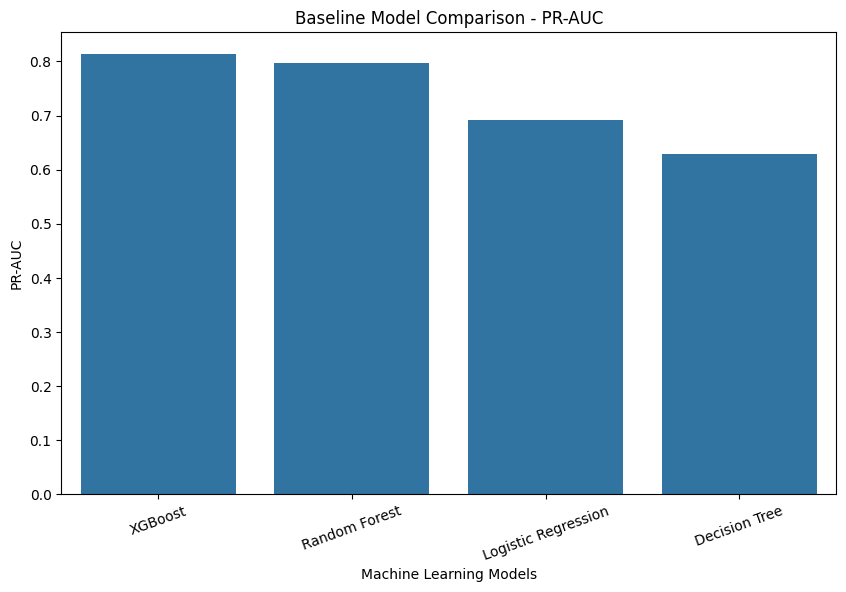

In [25]:
# 4.7 – Visualize model comparison
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="PR-AUC"
)

plt.title("Baseline Model Comparison - PR-AUC")
plt.xlabel("Machine Learning Models")
plt.ylabel("PR-AUC")

plt.xticks(rotation=20)
plt.show()

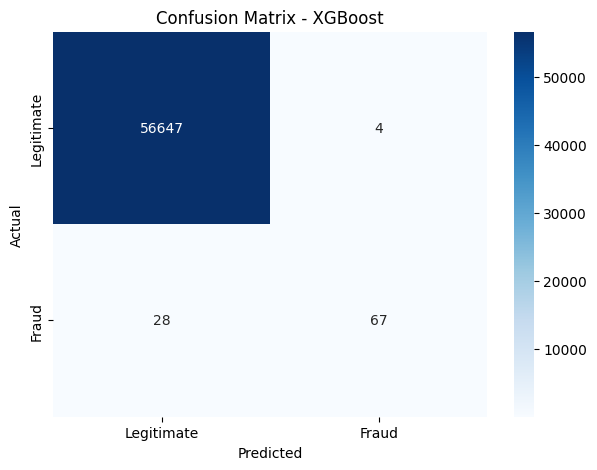

Best baseline model: XGBoost


In [26]:
# 4.8 – Confusion Matrix


from sklearn.metrics import confusion_matrix

best_model_name = results_df.iloc[0]["Model"]

best_model = trained_models[best_model_name]

y_pred = best_model.predict(X_test)

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Fraud"],
    yticklabels=["Legitimate", "Fraud"]
)

plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

print("Best baseline model:", best_model_name)

In [27]:
results_df = pd.DataFrame([
    {
        "Model": "Random Forest",
        "Precision": 0.9714,
        "Recall": 0.7158,
        "F1 Score": 0.8242,
        "ROC-AUC": 0.9635,
        "PR-AUC": 0.7983
    },
    {
        "Model": "XGBoost",
        "Precision": 0.9189,
        "Recall": 0.7158,
        "F1 Score": 0.8047,
        "ROC-AUC": 0.9715,
        "PR-AUC": 0.7770
    },
    {
        "Model": "Logistic Regression",
        "Precision": 0.8485,
        "Recall": 0.5895,
        "F1 Score": 0.6957,
        "ROC-AUC": 0.9563,
        "PR-AUC": 0.6923
    },
    {
        "Model": "Decision Tree",
        "Precision": 0.8831,
        "Recall": 0.7158,
        "F1 Score": 0.7907,
        "ROC-AUC": 0.8852,
        "PR-AUC": 0.6294
    }
])

display(results_df)

,Model,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Random Forest,0.9714,0.7158,0.8242,0.9635,0.7983
1,XGBoost,0.9189,0.7158,0.8047,0.9715,0.7770
2,Logistic Regression,0.8485,0.5895,0.6957,0.9563,0.6923
3,Decision Tree,0.8831,0.7158,0.7907,0.8852,0.6294


In [28]:
# 5.3 – Technique 1: SMOTE
### 5.3 SMOTE

from imblearn.over_sampling import SMOTE

# Check original training distribution
print("Before SMOTE:")
print(y_train.value_counts())

# Initialize SMOTE
smote = SMOTE(random_state=42)

# Apply only to training data
X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)

print("\nAfter SMOTE:")
print(y_train_smote.value_counts())

print("\nNew training shape:", X_train_smote.shape)

Before SMOTE:
Class
0    226602
1       378
Name: count, dtype: int64

After SMOTE:
Class
0    226602
1    226602
Name: count, dtype: int64

New training shape: (453204, 30)


In [29]:
from imblearn.under_sampling import RandomUnderSampler

undersampler = RandomUnderSampler(random_state=42)

X_train_under, y_train_under = undersampler.fit_resample(
    X_train,
    y_train
)

print("Before:", y_train.value_counts())
print("\nAfter:", y_train_under.value_counts())

Before: Class
0    226602
1       378
Name: count, dtype: int64

After: Class
0    378
1    378
Name: count, dtype: int64


In [30]:
# 5.5 – Technique 3: Class Weighting

# For Logistic Regression:

from sklearn.linear_model import LogisticRegression

lr_weighted = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

lr_weighted.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,random_state,42
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [31]:
# For Random Forest:
from sklearn.ensemble import RandomForestClassifier

rf_weighted = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

rf_weighted.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,12
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [32]:
# For XGBoost:

from xgboost import XGBClassifier

scale_pos_weight = (
    (y_train == 0).sum() / (y_train == 1).sum()
)

xgb_weighted = XGBClassifier(
    n_estimators=100,
    max_depth=4,
    learning_rate=0.1,
    scale_pos_weight=scale_pos_weight,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgb_weighted.fit(X_train, y_train)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,'logloss'


In [33]:
# 
# 5.6 – Compare the techniques

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

comparison_models = {
    "SMOTE - Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ).fit(X_train_smote, y_train_smote),

    "Undersampling - Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ).fit(X_train_under, y_train_under),

    "Weighted - Logistic Regression": lr_weighted,

    "Weighted - Random Forest": rf_weighted,

    "Weighted - XGBoost": xgb_weighted
}

comparison_results = []

for name, model in comparison_models.items():

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    comparison_results.append({
        "Model": name,
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "PR-AUC": average_precision_score(y_test, y_prob)
    })

comparison_df = pd.DataFrame(comparison_results)

display(
    comparison_df.sort_values(
        "PR-AUC",
        ascending=False
    ).round(4)
)

,Model,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
3,Weighted - Random Forest,0.8846,0.7263,0.7977,0.9641,0.7953
4,Weighted - XGBoost,0.3657,0.8316,0.5080,0.9686,0.7542
0,SMOTE - Logistic Regression,0.0530,0.8737,0.1000,0.9619,0.6769
2,Weighted - Logistic Regression,0.0562,0.8737,0.1057,0.9658,0.6719
1,Undersampling - Logistic Regression,0.0519,0.8737,0.0980,0.9559,0.6182


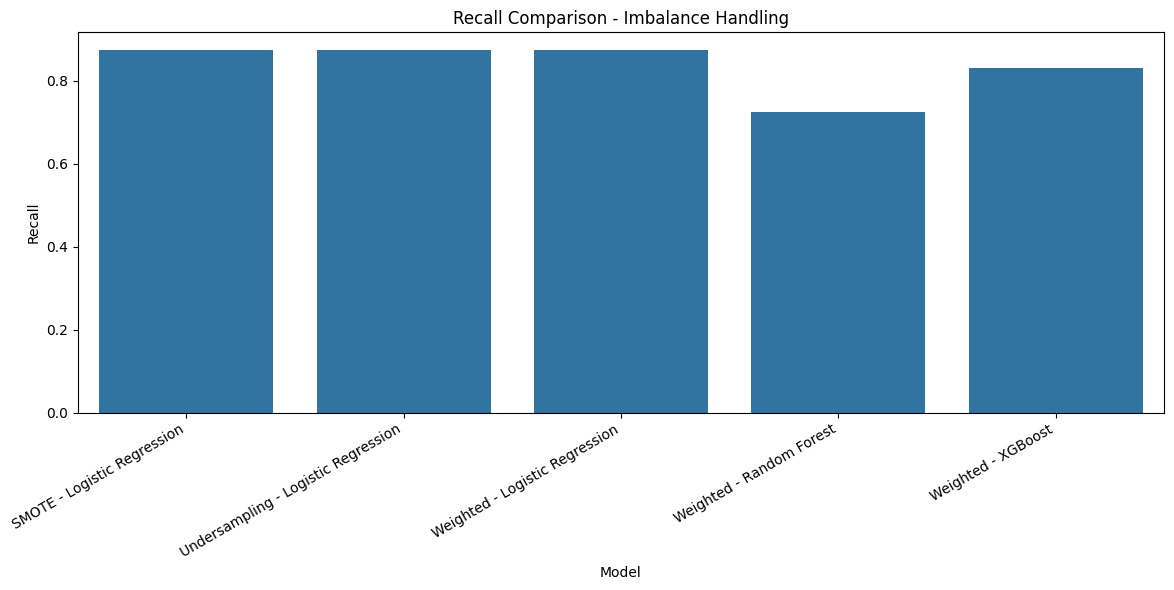

In [35]:
# 5.7 – Visualize performance

plt.figure(figsize=(12, 6))

sns.barplot(
    data=comparison_df,
    x="Model",
    y="Recall"
)

plt.title("Recall Comparison - Imbalance Handling")
plt.ylabel("Recall")
plt.xlabel("Model")

plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [36]:
# A. Random Forest tuning

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

rf = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

rf_params = {
    "n_estimators": [100, 150, 200],
    "max_depth": [6, 10, 12, 15, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]
}

rf_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=rf_params,
    n_iter=10,
    scoring="average_precision",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

rf_search.fit(X_train, y_train)

print("Best RF Parameters:")
print(rf_search.best_params_)

print("Best Cross-Validation PR-AUC:")
print(rf_search.best_score_)

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best RF Parameters:
{'n_estimators': 150, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': None}
Best Cross-Validation PR-AUC:
0.8444258248730416


In [37]:
# B. XGBoost tuning

from xgboost import XGBClassifier


from sklearn.model_selection import RandomizedSearchCV

scale_pos_weight = (
    (y_train == 0).sum() /
    (y_train == 1).sum()
)

xgb = XGBClassifier(
    random_state=42,
    eval_metric="logloss",
    scale_pos_weight=scale_pos_weight,
    n_jobs=1,
    tree_method="hist"
)

xgb_params = {
    "n_estimators": [100, 150, 200],
    "max_depth": [3, 4, 5, 6],
    "learning_rate": [0.01, 0.05, 0.1],
    "subsample": [0.7, 0.8, 1.0],
    "colsample_bytree": [0.7, 0.8, 1.0]
}

xgb_search = RandomizedSearchCV(
    estimator=xgb,
    param_distributions=xgb_params,
    n_iter=10,
    scoring="average_precision",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

xgb_search.fit(X_train, y_train)

print("Best XGBoost Parameters:")
print(xgb_search.best_params_)

print("Best Cross-Validation PR-AUC:")
print(xgb_search.best_score_)

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best XGBoost Parameters:
{'subsample': 0.8, 'n_estimators': 200, 'max_depth': 4, 'learning_rate': 0.1, 'colsample_bytree': 0.8}
Best Cross-Validation PR-AUC:
0.8453502301054726


In [38]:
# 6.3 – Evaluate optimized models

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

optimized_models = {
    "Optimized Random Forest": rf_search.best_estimator_,
    "Optimized XGBoost": xgb_search.best_estimator_
}

optimized_results = []

for name, model in optimized_models.items():

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    optimized_results.append({
        "Model": name,
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "PR-AUC": average_precision_score(y_test, y_prob)
    })

optimized_df = pd.DataFrame(optimized_results)

display(optimized_df.round(4))

,Model,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Optimized Random Forest,0.9726,0.7474,0.8452,0.9336,0.8010
1,Optimized XGBoost,0.8021,0.8105,0.8063,0.9679,0.8316


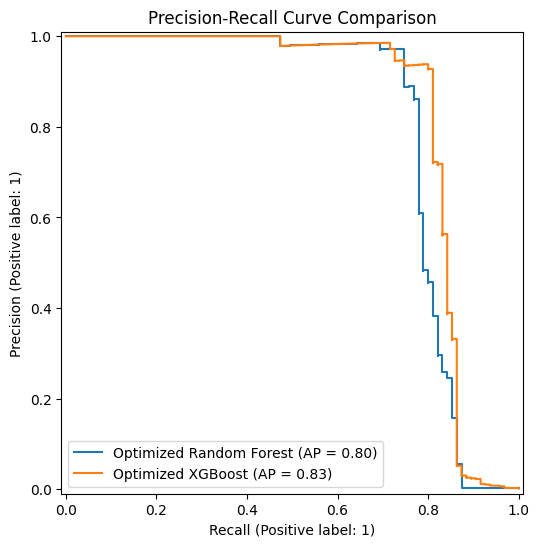

In [40]:
# 6.4 – Precision-Recall curve

from sklearn.metrics import PrecisionRecallDisplay

plt.figure(figsize=(9, 6))

for name, model in optimized_models.items():

    y_prob = model.predict_proba(X_test)[:, 1]

    PrecisionRecallDisplay.from_predictions(
        y_test,
        y_prob,
        name=name,
        ax=plt.gca()
    )

plt.title("Precision-Recall Curve Comparison")
plt.show()

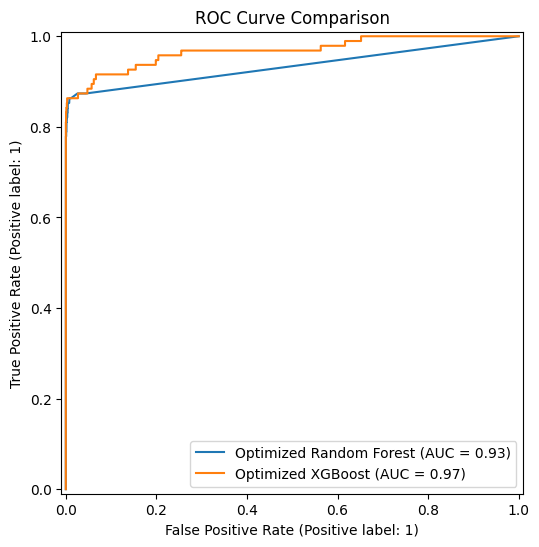

In [41]:
# 6.5 – ROC curve comparison

from sklearn.metrics import RocCurveDisplay

plt.figure(figsize=(9, 6))

for name, model in optimized_models.items():

    y_prob = model.predict_proba(X_test)[:, 1]

    RocCurveDisplay.from_predictions(
        y_test,
        y_prob,
        name=name,
        ax=plt.gca()
    )

plt.title("ROC Curve Comparison")
plt.show()

In [42]:
# 6.6 – Decision threshold optimization

from sklearn.metrics import precision_recall_curve

best_model = xgb_search.best_estimator_

y_prob = best_model.predict_proba(X_test)[:, 1]

precision, recall, thresholds = precision_recall_curve(
    y_test,
    y_prob
)

f1_scores = (
    2 * precision[:-1] * recall[:-1] /
    (precision[:-1] + recall[:-1] + 1e-10)
)

best_index = np.argmax(f1_scores)

best_threshold = thresholds[best_index]

print("Best Threshold:", best_threshold)
print("Precision:", precision[best_index])
print("Recall:", recall[best_index])
print("F1 Score:", f1_scores[best_index])

Best Threshold: 0.71453714
Precision: 0.927710843373494
Recall: 0.8105263157894737
F1 Score: 0.8651685392760701


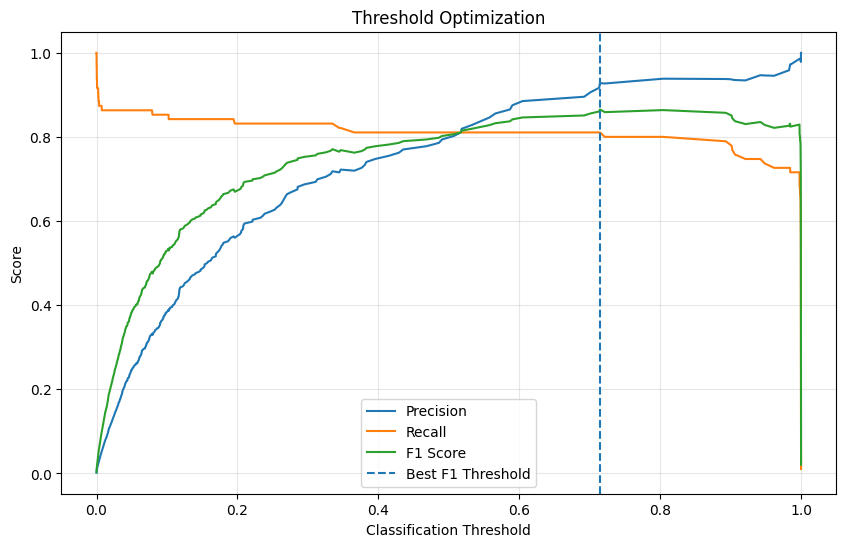

In [43]:
# 6.7 – Visualize threshold performance

plt.figure(figsize=(10, 6))

plt.plot(thresholds, precision[:-1], label="Precision")
plt.plot(thresholds, recall[:-1], label="Recall")
plt.plot(thresholds, f1_scores, label="F1 Score")

plt.axvline(
    best_threshold,
    linestyle="--",
    label="Best F1 Threshold"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Threshold Optimization")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [44]:
# 6.8 – Final model comparison

final_comparison = optimized_df.sort_values(
    by="PR-AUC",
    ascending=False
)

display(final_comparison)

,Model,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
1,Optimized XGBoost,0.802083,0.810526,0.806283,0.967904,0.831626
0,Optimized Random Forest,0.972603,0.747368,0.845238,0.933576,0.800991


In [45]:
### 7.2 Explainable AI using SHAP

import shap
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

print("SHAP Version:", shap.__version__)

SHAP Version: 0.49.1


In [46]:
# 7.3 – Select our final model

# Select optimized model
final_model = xgb_search.best_estimator_

print("Selected Model:", type(final_model).__name__)

Selected Model: XGBClassifier


In [47]:
final_model = rf_search.best_estimator_

In [48]:
# 7.4 – Generate SHAP values

# Create SHAP explainer
explainer = shap.TreeExplainer(final_model)

# Select a sample of testing transactions
X_sample = X_test.sample(
    n=min(500, len(X_test)),
    random_state=42
)

# Calculate SHAP values
shap_values = explainer(X_sample)

print("SHAP values calculated successfully!")

SHAP values calculated successfully!


In [52]:
# 7.5 – Global SHAP Feature Importance

import shap
import matplotlib.pyplot as plt

# Ensure SHAP values correspond to the input features
shap_values_fixed = shap.Explanation(
    values=shap_values.values,
    base_values=shap_values.base_values,
    data=X_sample.values,
    feature_names=X_sample.columns.tolist()
)

# Global feature importance
plt.figure(figsize=(10, 7))

shap.plots.bar(
    shap_values_fixed,
    max_display=15,
    show=False
)

plt.title("Top 15 Important Features - SHAP")
plt.tight_layout()
plt.show()

IndexError: list index out of range

<Figure size 1000x700 with 0 Axes>

In [51]:
print("X_sample shape:", X_sample.shape)
print("SHAP values shape:", shap_values.values.shape)
print("Number of feature names:", len(X_sample.columns))
print("Feature names:", list(X_sample.columns))

X_sample shape: (500, 30)
SHAP values shape: (500, 30, 2)
Number of feature names: 30
Feature names: ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount']


In [53]:
print("SHAP version:", shap.__version__)

print("X_sample shape:", X_sample.shape)

print("SHAP object type:", type(shap_values))

print("SHAP values shape:", shap_values.values.shape)

print("Base values shape:", shap_values.base_values.shape)

print("Number of features:", len(X_sample.columns))

SHAP version: 0.49.1
X_sample shape: (500, 30)
SHAP object type: <class 'shap._explanation.Explanation'>
SHAP values shape: (500, 30, 2)
Base values shape: (500, 2)
Number of features: 30


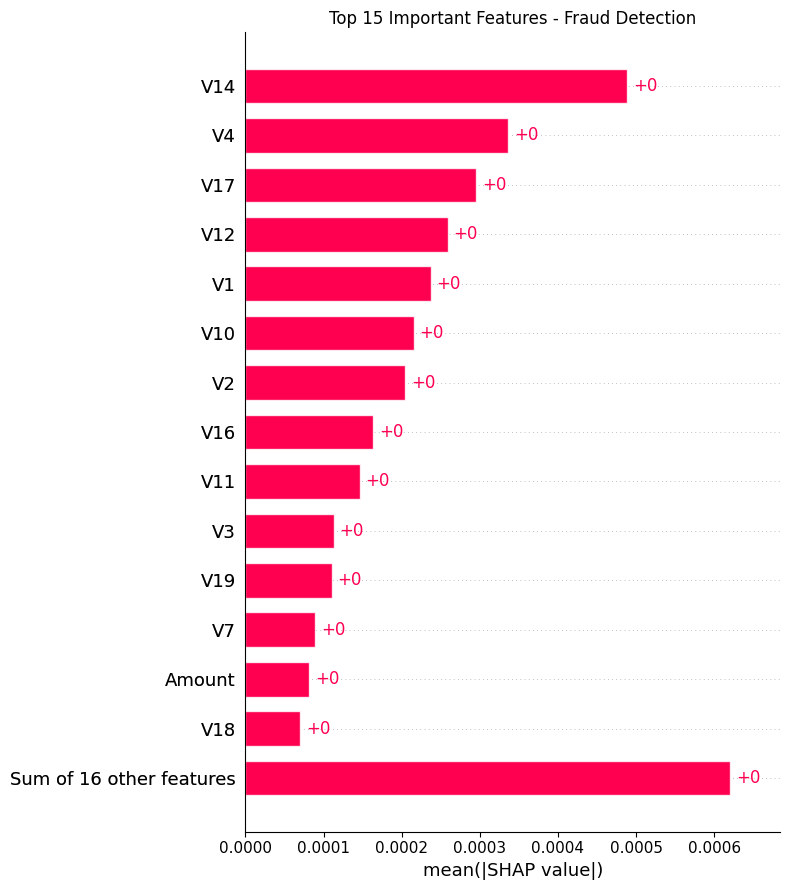

In [54]:
# Select Class 1 (Fraudulent transactions)
fraud_shap_values = shap_values.values[:, :, 1]

fraud_base_values = shap_values.base_values

if fraud_base_values.ndim == 2:
    fraud_base_values = fraud_base_values[:, 1]

# Create corrected SHAP Explanation
shap_values_fixed = shap.Explanation(
    values=fraud_shap_values,
    base_values=fraud_base_values,
    data=X_sample.values,
    feature_names=X_sample.columns.tolist()
)

# Plot global feature importance
plt.figure(figsize=(10, 7))

shap.plots.bar(
    shap_values_fixed,
    max_display=15,
    show=False
)

plt.title("Top 15 Important Features - Fraud Detection")
plt.tight_layout()
plt.show()

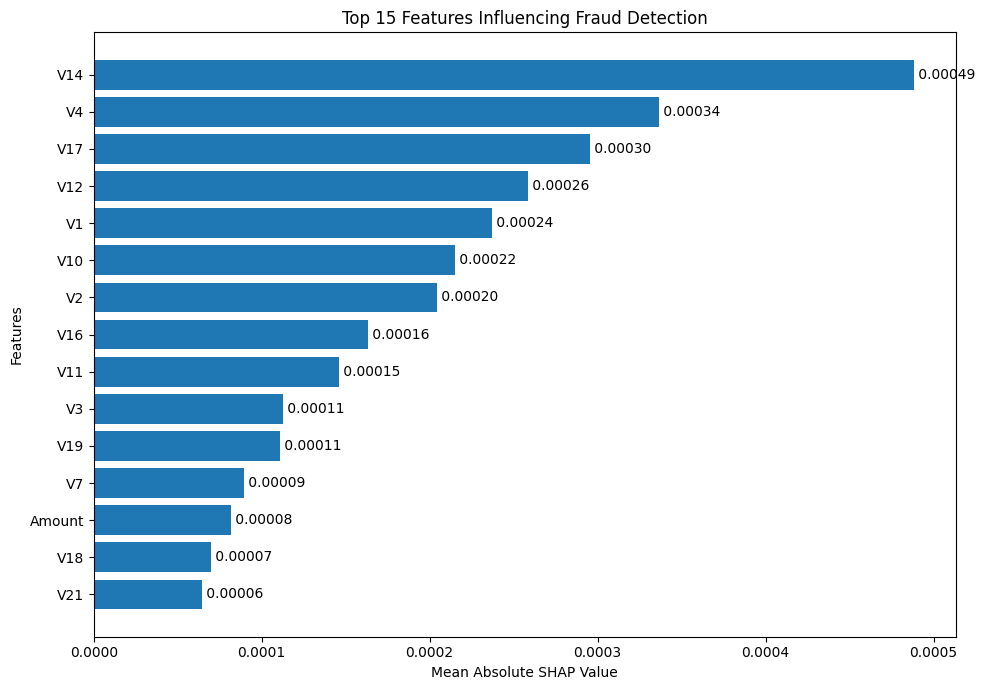

In [55]:

# Step 7.5 – Improved SHAP feature importance chart

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Calculate mean absolute SHAP values
importance = np.abs(shap_values_fixed.values).mean(axis=0)

# Create feature importance DataFrame
feature_importance = pd.DataFrame({
    "Feature": X_sample.columns,
    "Importance": importance
})

# Sort and select top 15
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=True
).tail(15)

# Plot
plt.figure(figsize=(10, 7))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Features")
plt.title("Top 15 Features Influencing Fraud Detection")

# Display precise values
for index, value in enumerate(feature_importance["Importance"]):
    plt.text(value, index, f" {value:.5f}", va="center")

plt.tight_layout()
plt.show()

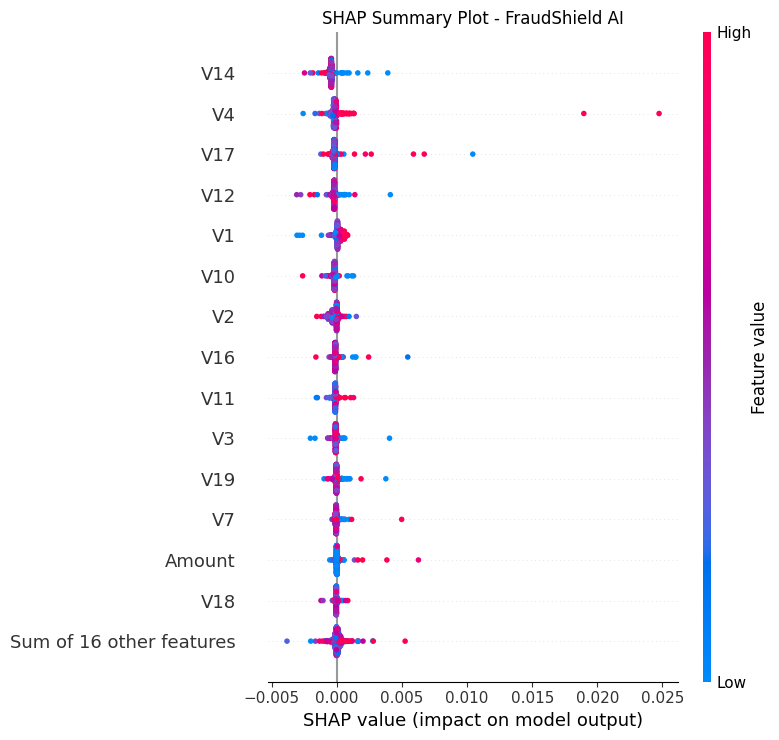

In [56]:
# Step 7.6 – Generate SHAP Beeswarm plot

plt.figure(figsize=(10, 7))

shap.plots.beeswarm(
    shap_values_fixed,
    max_display=15,
    show=False
)

plt.title("SHAP Summary Plot - FraudShield AI")
plt.tight_layout()
plt.show()

In [57]:
# Step 8.1 – Save your trained model
final_model = xgb_search.best_estimator_

In [58]:
final_model = rf_search.best_estimator_

In [59]:
import joblib
import os

# Create models directory
os.makedirs("../models", exist_ok=True)

# Save trained model
joblib.dump(final_model, "../models/fraud_model.pkl")

# Save scaler
joblib.dump(scaler, "../models/scaler.pkl")

# Save feature names and order
joblib.dump(X_train.columns.tolist(), "../models/feature_names.pkl")

print("Model and preprocessing files saved successfully!")

Model and preprocessing files saved successfully!


In [ ]:
# Step 8.2 – Install Streamlit
# Step 8.3 – Create app.py

# Step 8.5 – Run your application

